# LinkedIn Job Market Analysis

## Problem Definition

This project explores historical LinkedIn job postings (2023–2024) to identify advertised job-market patterns, locations, salaries, experience levels, and skills mentioned in job descriptions.

**Source:** [LinkedIn Job Postings dataset (Kaggle)](https://www.kaggle.com/datasets/arshkon/linkedin-job-postings)

### Research Questions

1. What are the most common job titles?
2. Which locations have the most job postings?
3. How are job postings distributed across experience levels?
4. How do salaries vary by experience level?
5. How does work type relate to salary?
6. What is the distribution of annual salaries?
7. What are the most frequently mentioned skills in job postings?
8. What are the top 5 skills for each job title?
9. How do salaries vary across different locations?
10. Do jobs mentioning certain skills tend to offer higher salaries?



In [1]:
# Download data from Kaggle (internet connection required)
!pip -q install kagglehub
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_style("whitegrid")
path = kagglehub.dataset_download("arshkon/linkedin-job-postings")


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
c:\Users\HUAWEI\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Load the same postings file used in the analysis
df = pd.read_csv(os.path.join(path, "postings.csv"))

In [3]:
# Display first 5 rows
df.head()

,job_id,company_name,title,description,max_salary,pay_period,location,company_id,views,med_salary,...,skills_desc,listed_time,posting_domain,sponsored,work_type,currency,compensation_type,normalized_salary,zip_code,fips
0,921716,Corcoran Sawyer Smith,Marketing Coordinator,Job descriptionA leading real estate firm in N...,20.0,HOURLY,"Princeton, NJ",2774458.0,20.0,NaN,...,Requirements: \n\nWe are seeking a College or ...,1.713398e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,38480.0,8540.0,34021.0
1,1829192,NaN,Mental Health Therapist/Counselor,"At Aspen Therapy and Wellness , we are committ...",50.0,HOURLY,"Fort Collins, CO",NaN,1.0,NaN,...,NaN,1.712858e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,83200.0,80521.0,8069.0
2,10998357,The National Exemplar,Assitant Restaurant Manager,The National Exemplar is accepting application...,65000.0,YEARLY,"Cincinnati, OH",64896719.0,8.0,NaN,...,We are currently accepting resumes for FOH - A...,1.713278e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,55000.0,45202.0,39061.0
3,23221523,"Abrams Fensterman, LLP",Senior Elder Law / Trusts and Estates Associat...,Senior Associate Attorney - Elder Law / Trusts...,175000.0,YEARLY,"New Hyde Park, NY",766262.0,16.0,NaN,...,This position requires a baseline understandin...,1.712896e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,157500.0,11040.0,36059.0
4,35982263,NaN,Service Technician,Looking for HVAC service tech with experience ...,80000.0,YEARLY,"Burlington, IA",NaN,3.0,NaN,...,NaN,1.713452e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,70000.0,52601.0,19057.0


In [4]:
# Dataset dimensions
df.shape

(123849, 31)

In [5]:
# Column names
df.columns

Index(['job_id', 'company_name', 'title', 'description', 'max_salary',
       'pay_period', 'location', 'company_id', 'views', 'med_salary',
       'min_salary', 'formatted_work_type', 'applies', 'original_listed_time',
       'remote_allowed', 'job_posting_url', 'application_url',
       'application_type', 'expiry', 'closed_time',
       'formatted_experience_level', 'skills_desc', 'listed_time',
       'posting_domain', 'sponsored', 'work_type', 'currency',
       'compensation_type', 'normalized_salary', 'zip_code', 'fips'],
      dtype='object')

In [6]:
# Data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 123849 entries, 0 to 123848
Data columns (total 31 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   job_id                      123849 non-null  int64  
 1   company_name                122130 non-null  object 
 2   title                       123849 non-null  object 
 3   description                 123842 non-null  object 
 4   max_salary                  29793 non-null   float64
 5   pay_period                  36073 non-null   object 
 6   location                    123849 non-null  object 
 7   company_id                  122132 non-null  float64
 8   views                       122160 non-null  float64
 9   med_salary                  6280 non-null    float64
 10  min_salary                  29793 non-null   float64
 11  formatted_work_type         123849 non-null  object 
 12  applies                     23320 non-null   float64
 13  original_liste

In [7]:
# Statistical summary of numerical columns
df.describe()

,job_id,max_salary,company_id,views,med_salary,min_salary,applies,original_listed_time,remote_allowed,expiry,closed_time,listed_time,sponsored,normalized_salary,zip_code,fips
count,1.238490e+05,2.979300e+04,1.221320e+05,122160.000000,6280.000000,2.979300e+04,23320.000000,1.238490e+05,15246.0,1.238490e+05,1.073000e+03,1.238490e+05,123849.0,3.607300e+04,102977.000000,96434.000000
mean,3.896402e+09,9.193942e+04,1.220401e+07,14.618247,22015.619876,6.491085e+04,10.591981,1.713152e+12,1.0,1.716213e+12,1.712928e+12,1.713204e+12,0.0,2.053270e+05,50400.491887,28713.879887
std,8.404355e+07,7.011101e+05,2.554143e+07,85.903598,52255.873846,4.959738e+05,29.047395,4.848209e+08,0.0,2.321394e+09,3.622893e+08,3.989122e+08,0.0,5.097627e+06,30252.232515,16015.929825
min,9.217160e+05,1.000000e+00,1.009000e+03,1.000000,0.000000,1.000000e+00,1.000000,1.701811e+12,1.0,1.712903e+12,1.712346e+12,1.711317e+12,0.0,0.000000e+00,1001.000000,1003.000000
25%,3.894587e+09,4.828000e+01,1.435200e+04,3.000000,18.940000,3.700000e+01,1.000000,1.712863e+12,1.0,1.715481e+12,1.712670e+12,1.712886e+12,0.0,5.200000e+04,24112.000000,13121.000000
50%,3.901998e+09,8.000000e+04,2.269650e+05,4.000000,25.500000,6.000000e+04,3.000000,1.713395e+12,1.0,1.716042e+12,1.712670e+12,1.713408e+12,0.0,8.150000e+04,48059.000000,29183.000000
75%,3.904707e+09,1.400000e+05,8.047188e+06,8.000000,2510.500000,1.000000e+05,8.000000,1.713478e+12,1.0,1.716088e+12,1.713283e+12,1.713484e+12,0.0,1.250000e+05,78201.000000,42077.000000
max,3.906267e+09,1.200000e+08,1.034730e+08,9975.000000,750000.000000,8.500000e+07,967.000000,1.713573e+12,1.0,1.729125e+12,1.713562e+12,1.713573e+12,0.0,5.356000e+08,99901.000000,56045.000000


In [8]:
# Count missing values
df.isnull().sum()

job_id                             0
company_name                    1719
title                              0
description                        7
max_salary                     94056
pay_period                     87776
location                           0
company_id                      1717
views                           1689
med_salary                    117569
min_salary                     94056
formatted_work_type                0
applies                       100529
original_listed_time               0
remote_allowed                108603
job_posting_url                    0
application_url                36665
application_type                   0
expiry                             0
closed_time                   122776
formatted_experience_level     29409
skills_desc                   121410
listed_time                        0
posting_domain                 39968
sponsored                          0
work_type                          0
currency                       87776
c

In [9]:
# Calculate missing values percentage
df.isnull().mean().sort_values(ascending=False) * 100

closed_time                   99.133622
skills_desc                   98.030666
med_salary                    94.929309
remote_allowed                87.689848
applies                       81.170619
min_salary                    75.944093
max_salary                    75.944093
currency                      70.873402
compensation_type             70.873402
pay_period                    70.873402
normalized_salary             70.873402
posting_domain                32.271556
application_url               29.604599
formatted_experience_level    23.745852
fips                          22.135827
zip_code                      16.852780
company_name                   1.387981
company_id                     1.386366
views                          1.363757
description                    0.005652
job_id                         0.000000
title                          0.000000
location                       0.000000
original_listed_time           0.000000
formatted_work_type            0.000000


In [10]:
# Check different salary payment periods
df["pay_period"].value_counts(dropna=False)

pay_period
NaN         87776
YEARLY      20628
HOURLY      14741
MONTHLY       518
WEEKLY        177
BIWEEKLY        9
Name: count, dtype: int64

### Salary Payment Period Analysis

The dataset contains five salary payment periods: YEARLY, HOURLY, MONTHLY, WEEKLY, and BIWEEKLY.

Around 70.87% of job postings have missing salary information.

**Key Finding:** Salaries use different payment periods, so they cannot be compared directly. I used `normalized_salary` for annual salary comparisons, while keeping potential outliers for further investigation.

In [11]:
# Check normalized salary statistics
df["normalized_salary"].describe()

count    3.607300e+04
mean     2.053270e+05
std      5.097627e+06
min      0.000000e+00
25%      5.200000e+04
50%      8.150000e+04
75%      1.250000e+05
max      5.356000e+08
Name: normalized_salary, dtype: float64

In [12]:
# Show the 10 highest normalized salaries
df.nlargest(10, "normalized_salary")[
    ["title", "max_salary", "pay_period", "normalized_salary" , "currency"]
]

,title,max_salary,pay_period,normalized_salary,currency
9237,Intellectual Property Associate (246215),275000.0,HOURLY,535600000.0,USD
98888,"Case Manager RN, Pedi Rheumatology",196570.0,HOURLY,362408800.0,USD
13614,Cloud Domain Architect,150000.0,HOURLY,286000000.0,USD
89082,Cloud Domain Architect,150000.0,HOURLY,286000000.0,USD
60038,Billing Supervisor (246521),125000.0,HOURLY,260000000.0,USD
102481,Manager - Clinical Applications Support - Anci...,123094.0,HOURLY,230423440.0,USD
71845,Sharepoint Developer,120000.0,HOURLY,228800000.0,USD
72585,Trial Paralegal - Hybrid in OC or LA!,100000.0,HOURLY,187200000.0,USD
17646,DCS Technician,80000.0,HOURLY,156000000.0,USD
87241,Full Time Field Service Technician – Anaheim/P...,68000.0,HOURLY,135200000.0,USD


In [13]:
# Check hourly salaries above 1000
df[
    (df["pay_period"] == "HOURLY") &
    (df["max_salary"] > 1000)
].shape[0]

29

In [14]:
# Original salary statistics
print("Original Mean:", df["normalized_salary"].mean())
print("Original Median:", df["normalized_salary"].median())

Original Mean: 205327.03684958277
Original Median: 81500.0


In [15]:
# Diagnostic comparison only; original postings are NOT removed
salary_check = df.loc[
    ~((df["pay_period"] == "HOURLY") & (df["max_salary"] > 1000)),
    "normalized_salary"
]
print("Original mean:", df["normalized_salary"].mean())
print("Mean excluding flagged hourly postings (diagnostic only):", salary_check.mean())
print("Original median:", df["normalized_salary"].median())
print("Median excluding flagged hourly postings (diagnostic only):", salary_check.median())

Original mean: 205327.03684958277
Mean excluding flagged hourly postings (diagnostic only): 98672.45345341804
Original median: 81500.0
Median excluding flagged hourly postings (diagnostic only): 81369.79999999999


Excluding 29 potentially misclassified hourly salary records reduced the mean annual salary from $205,327 to $98,672, while the median remained nearly unchanged. This shows that the median is more reliable for comparing salaries in this dataset.

In [16]:
# Count completely duplicated rows
df.duplicated().sum()

np.int64(0)

In [17]:
# Check duplicate job IDs
df["job_id"].duplicated().sum()

np.int64(0)

### Duplicate Values Analysis

I checked for duplicate rows and duplicate job IDs.

- Duplicate rows: 0
- Duplicate job IDs: 0

No duplicates were found, so no rows need to be removed for duplication.

In [18]:
# Check date columns
df[["original_listed_time", "listed_time", "expiry"]].head()

,original_listed_time,listed_time,expiry
0,1.713398e+12,1.713398e+12,1.715990e+12
1,1.712858e+12,1.712858e+12,1.715450e+12
2,1.713278e+12,1.713278e+12,1.715870e+12
3,1.712896e+12,1.712896e+12,1.715488e+12
4,1.713452e+12,1.713452e+12,1.716044e+12


In [19]:
# Convert listed_time to datetime
df["listed_time"] = pd.to_datetime(
    df["listed_time"],
    unit="ms"
)

In [20]:
# Check the result
df["listed_time"].head()

0   2024-04-17 23:45:08
1   2024-04-11 17:51:27
2   2024-04-16 14:26:54
3   2024-04-12 04:23:32
4   2024-04-18 14:52:23
Name: listed_time, dtype: datetime64[ns]

In [21]:
# Convert remaining date columns
df["original_listed_time"] = pd.to_datetime(
    df["original_listed_time"],
    unit="ms"
)

df["expiry"] = pd.to_datetime(
    df["expiry"],
    unit="ms"
)

In [22]:
# Check converted date columns
df[["original_listed_time", "listed_time", "expiry"]].head()

,original_listed_time,listed_time,expiry
0,2024-04-17 23:45:08,2024-04-17 23:45:08,2024-05-17 23:45:08
1,2024-04-11 17:51:27,2024-04-11 17:51:27,2024-05-11 17:51:27
2,2024-04-16 14:26:54,2024-04-16 14:26:54,2024-05-16 14:26:54
3,2024-04-12 04:23:32,2024-04-12 04:23:32,2024-05-12 04:23:32
4,2024-04-18 14:52:23,2024-04-18 14:52:23,2024-05-18 14:52:23


### Data Type Conversion

I checked the date columns and found that they were stored as numerical timestamps.

I converted `listed_time`, `original_listed_time`, and `expiry` into datetime format using `pd.to_datetime()`.

 The dates are now easier to read and can be used for time-based analysis.

In [23]:
# Create the single cleaned dataset used in the analysis
columns_to_drop = [
    "closed_time", "zip_code", "fips", "posting_domain", "application_url",
    "application_type", "expiry", "sponsored", "compensation_type",
    "original_listed_time", "company_id"
]
df_cleaned = df.drop(columns=columns_to_drop).copy()

# Preserve original scope: remove rows missing fields needed in the notebook
# (limitation: views and company_name are not necessary for every question)
df_cleaned = df_cleaned.dropna(subset=["company_name", "views", "description"]).copy()

# Normalize job titles once BEFORE title-based counts / groupings
df_cleaned["title"] = df_cleaned["title"].astype("string").str.strip()
df_cleaned["title"] = df_cleaned["title"].replace("", pd.NA)

print("Original shape:", df.shape)
print("Cleaned shape:", df_cleaned.shape)
print("Missing values in core fields:")
print(df_cleaned[["company_name", "views", "description"]].isna().sum())

Original shape: (123849, 31)
Cleaned shape: (120497, 20)
Missing values in core fields:
company_name    0
views           0
description     0
dtype: int64


In [24]:
# Check missing values percentage
df_cleaned.isnull().mean().sort_values(ascending=False) * 100

skills_desc                   98.037296
med_salary                    94.870412
remote_allowed                87.989742
applies                       81.002017
max_salary                    76.005212
min_salary                    76.005212
pay_period                    70.875623
currency                      70.875623
normalized_salary             70.875623
formatted_experience_level    22.836253
company_name                   0.000000
job_id                         0.000000
description                    0.000000
title                          0.000000
location                       0.000000
views                          0.000000
formatted_work_type            0.000000
job_posting_url                0.000000
work_type                      0.000000
listed_time                    0.000000
dtype: float64

In [25]:
# Check experience levels including missing values
df_cleaned["formatted_experience_level"].value_counts(dropna=False)

formatted_experience_level
Mid-Senior level    40825
Entry level         36321
NaN                 27517
Associate            9524
Director             3679
Internship           1442
Executive            1189
Name: count, dtype: int64

In [26]:
# Keep only jobs with known experience levels
df_experience = df_cleaned.dropna(
    subset=["formatted_experience_level"]
)

# Check the result
df_experience.shape

(92980, 20)

In [27]:
# Create a dataset for salary analysis
df_salary = df_cleaned.dropna(
    subset=["normalized_salary"]
).copy()

# Check dataset size
df_salary.shape

(35094, 20)

In [28]:
# Check salary currencies
df_salary["currency"].value_counts(dropna=False)

currency
USD    35082
EUR        5
CAD        3
BBD        2
GBP        2
Name: count, dtype: int64

In [29]:
# Keep only USD salaries
df_salary = df_salary[
    df_salary["currency"] == "USD"
].copy()

# Check the result
df_salary.shape

(35082, 20)

### Salary Data Quality Flag for Main Comparisons

The following rules flag **possible** payment-period problems, without deleting original rows. Main salary charts use `df_salary_analysis`; diagnostic checks of the original distribution use `df_salary`. The flags are tentative and should not be treated as confirmed data errors.


In [30]:
# Flag suspected pay-period errors before the main salary analyses (no deletion)
df_salary["salary_flag"] = (
    ((df_salary["pay_period"] == "HOURLY") &
     (df_salary["max_salary"] > 1000))
    |
    ((df_salary["pay_period"] == "BIWEEKLY") &
     (df_salary["normalized_salary"] > 500000))
)

# Check flagged salaries
print("Flagged salaries:", df_salary["salary_flag"].sum())
print("Unflagged salaries:", (~df_salary["salary_flag"]).sum())

# Create a separate dataset for salary comparisons; original df_salary is preserved
df_salary_analysis = df_salary[
    ~df_salary["salary_flag"]
].copy()

# Check dataset size
print("Salary analysis shape:", df_salary_analysis.shape)

Flagged salaries: 35
Unflagged salaries: 35047
Salary analysis shape: (35047, 21)


In [31]:
# Inspect suspicious hourly salary records (no exclusion)
suspicious_salaries = df_salary.loc[
    (df_salary["pay_period"] == "HOURLY") &
    (df_salary["max_salary"] > 1000)
]
print(":Flagged hourly postings", len(suspicious_salaries))

:Flagged hourly postings 29


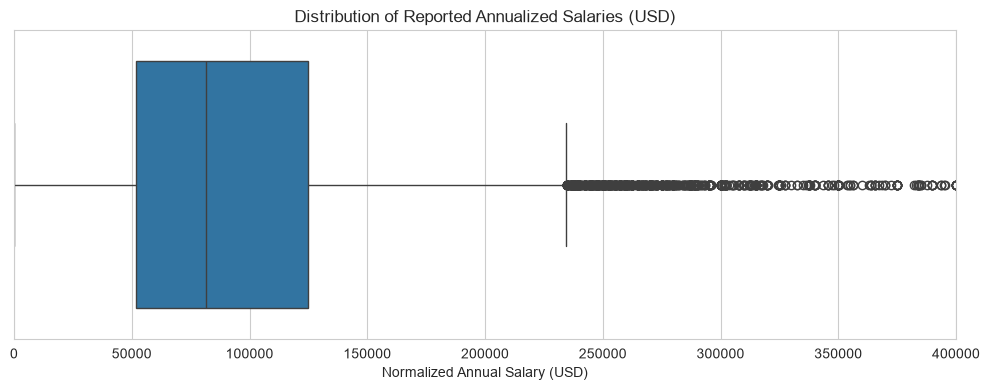

In [32]:
# Boxplot: keep all USD salary records; limit view for readability
plt.figure(figsize=(10, 4))
sns.boxplot(x=df_salary["normalized_salary"])
plt.xlim(0, 400000)  # Display range only; observations are NOT removed
plt.title("Distribution of Reported Annualized Salaries (USD)")
plt.xlabel("Normalized Annual Salary (USD)")
plt.tight_layout()
plt.show()

Most reported annualized salaries fall between approximately $52,000 and $125,000, with a median of around $82,000. The distribution is right-skewed, with several high-salary outliers. These values were retained for analysis, although some may reflect reporting or normalization errors.

In [33]:
# Investigate the largest reported salaries without deleting them
df_salary.nlargest(5, "normalized_salary")[[
    "title", "min_salary", "max_salary", "pay_period", "normalized_salary"
]]

,title,min_salary,max_salary,pay_period,normalized_salary
9237,Intellectual Property Associate (246215),240000.0,275000.0,HOURLY,535600000.0
98888,"Case Manager RN, Pedi Rheumatology",151900.0,196570.0,HOURLY,362408800.0
13614,Cloud Domain Architect,125000.0,150000.0,HOURLY,286000000.0
89082,Cloud Domain Architect,125000.0,150000.0,HOURLY,286000000.0
60038,Billing Supervisor (246521),125000.0,125000.0,HOURLY,260000000.0


In [34]:
# Compare reported annualized salaries by original payment period
df_salary.groupby("pay_period")["normalized_salary"].agg(
    ["count", "median", "mean", "max"]
).round(2)

,count,median,mean,max
pay_period,,,,
BIWEEKLY,9,1572805.0,1248661.56,2096744.0
HOURLY,14394,52364.0,336668.92,535600000.0
MONTHLY,501,51702.0,62825.67,1200000.0
WEEKLY,177,109148.0,111559.91,210548.0
YEARLY,20001,102500.0,120297.66,102500000.0


In [35]:
# Inspect BIWEEKLY salaries for possible normalization anomalies
df_salary.loc[
    df_salary["pay_period"] == "BIWEEKLY",
    ["title", "min_salary", "max_salary", "normalized_salary"]
]

,title,min_salary,max_salary,normalized_salary
36894,Assistant Manager Trainee,2057.0,2057.0,53482.0
86850,Assistant Manager Trainee,2134.0,2134.0,55484.0
86985,"Store Sales Representative - Chesterfield, VA",54009.0,66976.0,1572805.0
87136,R&D Scientific Programmer,71323.0,89965.0,2096744.0
99157,"Sales Representative, Residential Repaint",69496.0,87660.0,2043028.0
99442,"Sales Representative, Residential Repaint",2245.0,3366.0,72943.0
99498,"Sales Representative, Residential Repaint",64519.0,81434.0,1897389.0
107469,"Store Sales Representative - Cleveland, OH",54009.0,66976.0,1572805.0
122228,"Sales Representative, Residential Repaint, (Bi...",62639.0,81459.0,1873274.0


In [36]:
# Top 10 most common job titles
df_cleaned["title"].value_counts().head(10)

title
Sales Manager                      632
Customer Service Representative    357
Project Manager                    344
Senior Accountant                  234
Administrative Assistant           231
Executive Assistant                208
Receptionist                       198
Registered Nurse                   197
Staff Accountant                   196
Account Executive                  191
Name: count, dtype: Int64

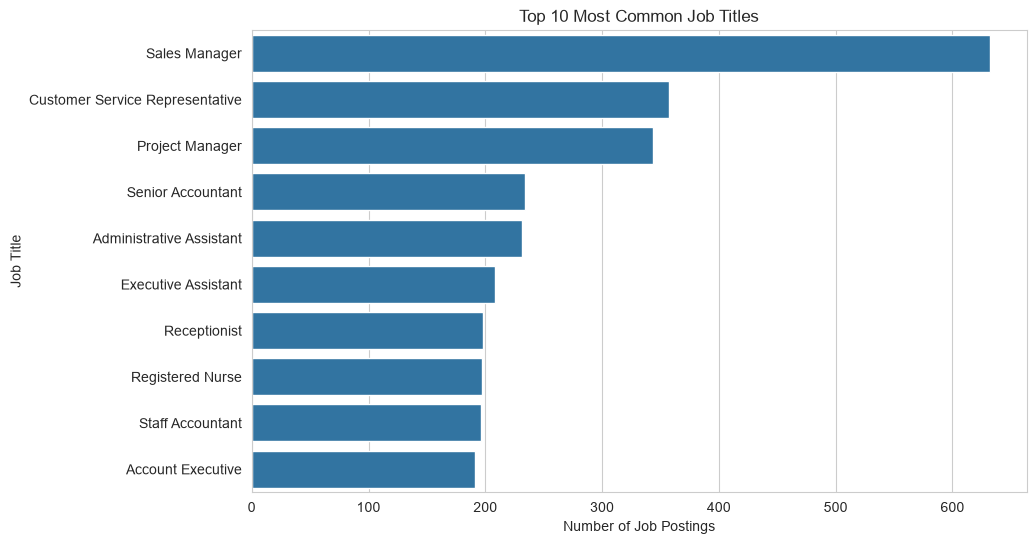

In [37]:
# Top 10 most common job titles
top_jobs = df_cleaned["title"].value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_jobs.values, y=top_jobs.index)

plt.title("Top 10 Most Common Job Titles")
plt.xlabel("Number of Job Postings")
plt.ylabel("Job Title")

plt.show()

Sales Manager is the most common job title in the dataset, with 632 postings, followed by Customer Service Representative (357) and Project Manager (344). This shows that sales, customer service, and management roles are well represented in the dataset.

In [38]:
# Top 10 locations by number of job postings
df_cleaned["location"].value_counts().head(10)

location
United States    7722
New York, NY     2695
Chicago, IL      1797
Houston, TX      1720
Dallas, TX       1352
Atlanta, GA      1332
Boston, MA       1153
Austin, TX       1071
Charlotte, NC    1056
Phoenix, AZ      1027
Name: count, dtype: int64

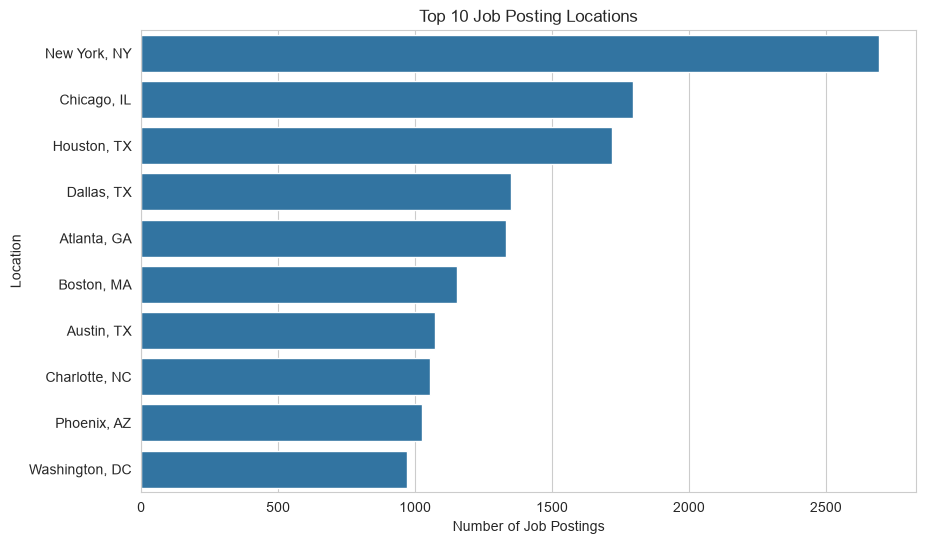

In [39]:
# Top 10 locations excluding the country-level label
top_locations = (
    df_cleaned.loc[
        df_cleaned["location"] != "United States",
        "location"
    ]
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_locations.values,
    y=top_locations.index
)

plt.title("Top 10 Job Posting Locations")
plt.xlabel("Number of Job Postings")
plt.ylabel("Location")

plt.show()

New York has the highest number of job postings (2,695), followed by Chicago (1,797) and Houston (1,720). This suggests that these cities are strongly represented in the dataset.

In [40]:
# Count jobs by experience level
df_experience["formatted_experience_level"].value_counts()

formatted_experience_level
Mid-Senior level    40825
Entry level         36321
Associate            9524
Director             3679
Internship           1442
Executive            1189
Name: count, dtype: int64

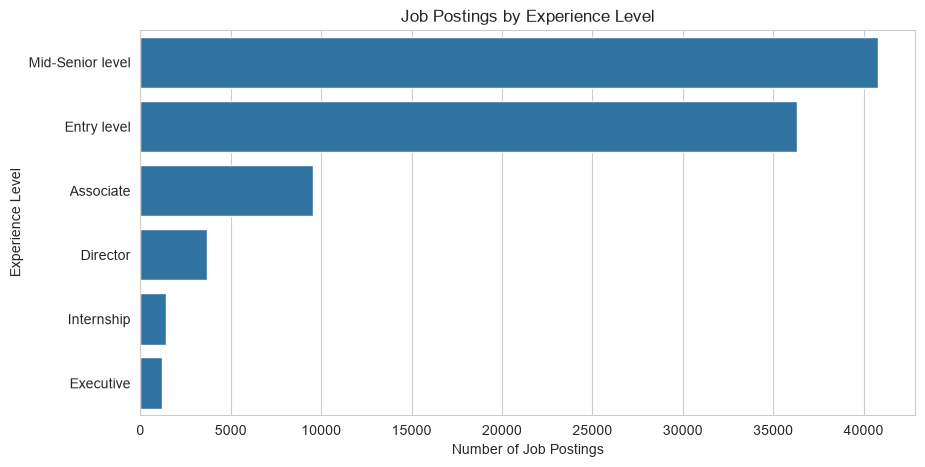

In [41]:
# Job postings by experience level
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df_experience,
    y="formatted_experience_level",
    order=df_experience["formatted_experience_level"].value_counts().index
)

plt.title("Job Postings by Experience Level")
plt.xlabel("Number of Job Postings")
plt.ylabel("Experience Level")

plt.show()

Mid-Senior level has the highest number of job postings (40,825), followed by Entry level (36,321). Internship and Executive positions have the fewest postings. This suggests that Mid-Senior and Entry-level roles are the most represented among jobs with a specified experience level.

In [42]:
# Jobs with known experience levels and USD salaries
df_salary_experience = df_salary_analysis.dropna(
    subset=["formatted_experience_level"]
).copy()

# Median salary by experience level
df_salary_experience.groupby(
    "formatted_experience_level"
)["normalized_salary"].median().sort_values()

formatted_experience_level
Internship           48048.0
Entry level          52052.0
Associate            72800.0
Mid-Senior level    107500.0
Director            167500.0
Executive           192500.0
Name: normalized_salary, dtype: float64

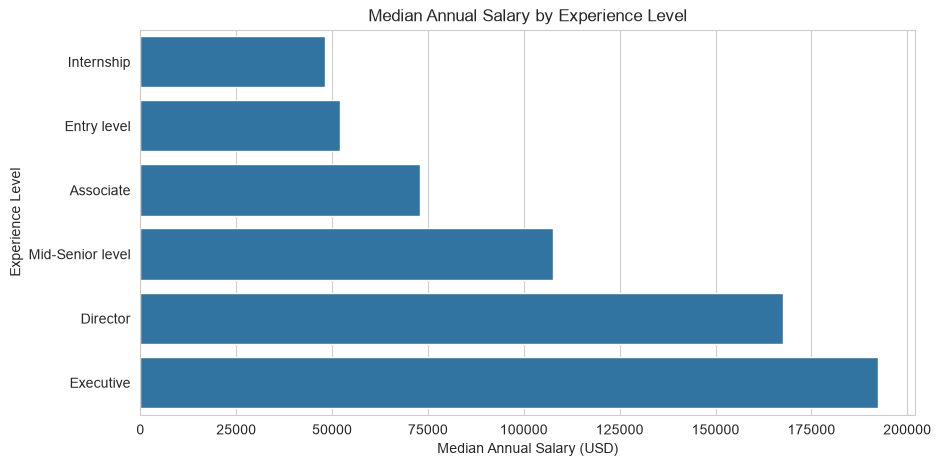

In [43]:
# Median annual salary by experience level
salary_by_experience = (
    df_salary_experience
    .groupby("formatted_experience_level")["normalized_salary"]
    .median()
    .sort_values()
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=salary_by_experience.values,
    y=salary_by_experience.index
)

plt.title("Median Annual Salary by Experience Level")
plt.xlabel("Median Annual Salary (USD)")
plt.ylabel("Experience Level")

plt.show()

Median annualized salaries generally increase with experience level in the analyzed salary subset. Compare the medians in the updated chart after running the notebook.


In [44]:
# Check available work types
df_salary_analysis["work_type"].value_counts(dropna=False)

work_type
FULL_TIME     28344
CONTRACT       3730
PART_TIME      2218
TEMPORARY       381
INTERNSHIP      236
OTHER           131
VOLUNTEER         7
Name: count, dtype: int64

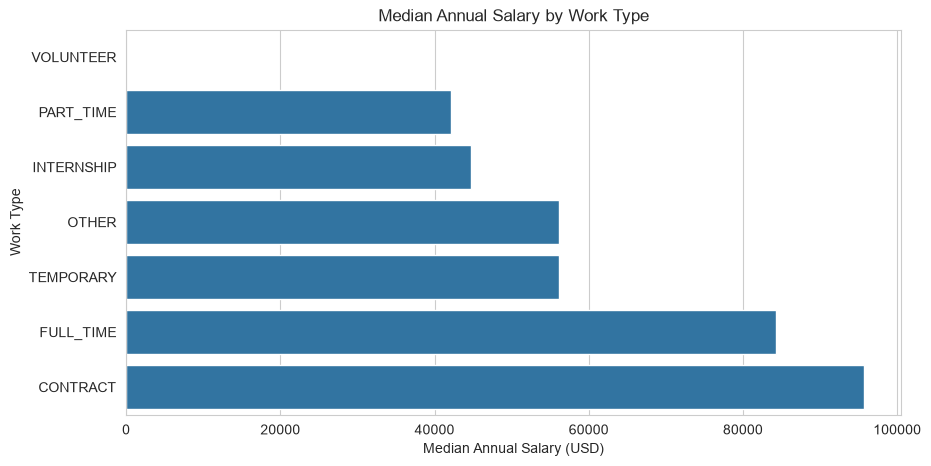

In [45]:
# Median annual salary by work type
salary_by_work_type = (
    df_salary_analysis.groupby("work_type")["normalized_salary"]
    .median()
    .sort_values()
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=salary_by_work_type.values,
    y=salary_by_work_type.index
)

plt.title("Median Annual Salary by Work Type")
plt.xlabel("Median Annual Salary (USD)")
plt.ylabel("Work Type")

plt.show()

Contract jobs have the highest median annualized salary at around $96,000, followed by Full-Time jobs at $84,000. Part-Time jobs have a lower median of around $42,000. These differences may depend on the type of job and working hours.

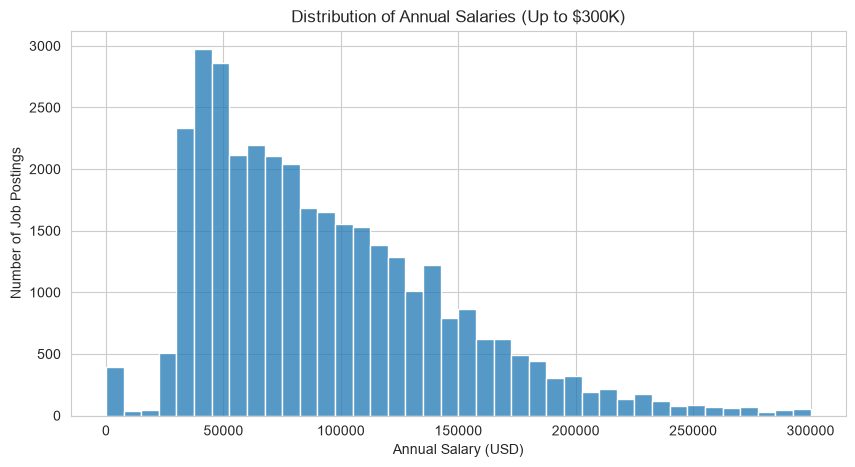

In [46]:
# Annual salary distribution (display range only)
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_salary_analysis,
    x="normalized_salary",
    bins=40,
    binrange=(0, 300000)
)
plt.title("Distribution of Annual Salaries (Up to $300K)")
plt.xlabel("Annual Salary (USD)")
plt.ylabel("Number of Job Postings")

plt.show()

### Annual Salary Distribution

Most annual salaries are between $35,000 and $100,000, with the highest number of jobs around $40,000–$50,000.

The distribution is right-skewed, meaning fewer jobs offer higher salaries.

The chart only shows salaries up to $300,000. Higher values are not displayed but remain in the dataset.

In [47]:
# Display a sample job description
print(df_cleaned["description"].iloc[0])

Job descriptionA leading real estate firm in New Jersey is seeking an administrative Marketing Coordinator with some experience in graphic design. You will be working closely with our fun, kind, ambitious members of the sales team and our dynamic executive team on a daily basis. This is an opportunity to be part of a fast-growing, highly respected real estate brokerage with a reputation for exceptional marketing and extraordinary culture of cooperation and inclusion.Who you are:You must be a well-organized, creative, proactive, positive, and most importantly, kind-hearted person. Please, be responsible, respectful, and cool-under-pressure. Please, be proficient in Adobe Creative Cloud (Indesign, Illustrator, Photoshop) and Microsoft Office Suite. Above all, have fantastic taste and be a good-hearted, fun-loving person who loves working with people and is eager to learn.Role:Our office is a fast-paced environment. You’ll work directly with a Marketing team and communicate daily with oth

In [48]:
# Skills to search for
skills = [
    # Data & Technology
    "Python", "SQL", "Excel", "Power BI", "Tableau",
    "Machine Learning", "Data Analysis", "Statistics",
    "Java", "JavaScript", "AWS", "Azure", "Git",
     "Spark", "Power Query", "Data Visualization",
    "Database Management", "Cybersecurity", "Linux",

    # Marketing & Design
    "Photoshop", "Illustrator", "InDesign",
    "Graphic Design", "SEO", "Google Analytics",
    "Social Media", "Digital Marketing",
    "Content Creation", "Brand Management",

    # Business & Management
    "Project Management", "Microsoft Office",
    "Communication", "Leadership", "Problem Solving",
    "Customer Service", "Sales", "Negotiation",
    "Time Management", "Strategic Planning",

    # Finance & Legal
    "Accounting", "Financial Analysis",
    "QuickBooks", "Budgeting", "Data Entry",
    "Risk Management", "Risk Assessment",
    "Model Validation", "Financial Planning",
    "Compliance", "Contract Management",
    "Legal Research",

    # Engineering & Maintenance
    "AutoCAD", "SolidWorks", "Electrical Engineering",
    "Circuit Design", "Troubleshooting",
    "Preventive Maintenance", "HVAC",
    "Quality Control", "Equipment Maintenance",
    "Safety Procedures", "PLC", "Revit",

    # Logistics & Operations
    "Inventory Management", "Forklift",
    "Warehouse Management", "Supply Chain",
    "Logistics", "Shipping", "Order Picking",
    "Material Handling", "Route Planning",

    # Healthcare
    "Patient Care", "Nursing", "CPR",
    "Electronic Health Records", "Patient Assessment",
    "Medical Terminology", "Clinical Documentation",

    # Hospitality & Services
    "Housekeeping", "Food Safety", "Food Preparation",
    "Cleaning", "Cash Handling", "POS",
    "Customer Relations"
]

# Note: This is a curated keyword list, not a complete skills taxonomy.
# A match means the phrase appeared in an advertisement; it does not prove
# the employer requires that skill or that every unlisted skill was absent.


In [49]:
import re

# Compile a single case-insensitive pattern with word boundaries
skill_pattern = re.compile(
    r"(?<!\w)(?:" +
    "|".join(re.escape(skill) for skill in sorted(skills, key=len, reverse=True)) +
    r")(?!\w)",
    flags=re.IGNORECASE
)
skill_lookup = {skill.lower(): skill for skill in skills}

def extract_skills(description):
    matches = skill_pattern.findall(str(description))
    return sorted({skill_lookup[match.lower()] for match in matches})

# Apply to ALL job descriptions, not just the example title
df_cleaned["extracted_skills"] = df_cleaned["description"].apply(extract_skills)

# Inspect a sample (the old substring-based method has been removed)
df_cleaned[["title", "extracted_skills"]].head()

,title,extracted_skills
0,Marketing Coordinator,"[Graphic Design, Illustrator, InDesign, Micros..."
2,Assitant Restaurant Manager,[]
3,Senior Elder Law / Trusts and Estates Associat...,[Communication]
5,Economic Development and Planning Intern,"[Communication, Data Analysis, Leadership, Mic..."
6,Producer,[]


In [50]:
# Check Skills Extraction Coverage
has_skills = df_cleaned["extracted_skills"].str.len() > 0

print("Total Jobs:", len(df_cleaned))
print("Jobs With Skills:", has_skills.sum())
print("Jobs Without Skills:", (~has_skills).sum())
print("Coverage:", round(has_skills.mean() * 100, 2), "%")

Total Jobs: 120497
Jobs With Skills: 109841
Jobs Without Skills: 10656
Coverage: 91.16 %


In [51]:
# Select Data Analyst job postings
job_title = "Data Analyst"

job_data = df_cleaned[
    df_cleaned["title"].str.lower() == job_title.lower()
]

# Count how many postings mention each skill
skill_counts = job_data["extracted_skills"].explode().value_counts()

# Calculate skill percentages
skill_percentages = (
    skill_counts / len(job_data) * 100
).round(2)

print("Job postings:", len(job_data))
print(skill_percentages.head(10))

Job postings: 132
extracted_skills
SQL                   71.21
Python                52.27
Communication         36.36
Excel                 36.36
Data Analysis         34.09
JavaScript            30.30
Statistics            25.00
Tableau               18.94
Data Visualization    14.39
Leadership            13.64
Name: count, dtype: float64


Among 132 Data Analyst job postings, SQL was the most frequently mentioned skill (71.21%), followed by Python (52.27%). Communication and Excel were each mentioned in 36.36% of postings, showing a mix of technical and workplace skills.

In [52]:
# Calculate skill percentages for all job titles
job_counts = df_cleaned.groupby("title").size()

skills_by_job = (
    df_cleaned[["title", "extracted_skills"]]
    .explode("extracted_skills")
    .dropna(subset=["extracted_skills"])
    .groupby(["title", "extracted_skills"])
    .size()
    .reset_index(name="skill_count")
)

skills_by_job["percentage"] = (
    skills_by_job["skill_count"]
    / skills_by_job["title"].map(job_counts)
    * 100
).round(2)

# Get top 5 skills for each job title
top5_skills = (
    skills_by_job
    .sort_values(
        ["title", "percentage", "skill_count", "extracted_skills"],
        ascending=[True, False, False, True]
    )
    .groupby("title")
    .head(5)
)

top5_skills.head(10)

,title,extracted_skills,skill_count,percentage
0,![,Compliance,1,100.0
1,"""A"" Electrician - 3rd Shift (Monday - Friday) ...",Communication,1,100.0
2,"""A"" Electrician - 3rd Shift (Monday - Friday) ...",Forklift,1,100.0
3,"""A"" Electrician - 3rd Shift (Monday - Friday) ...",Troubleshooting,1,100.0
4,"""Senior Integration Engineer - IBM ACE/IIB Adm...",Azure,1,100.0
5,"""Senior Integration Engineer - IBM ACE/IIB Adm...",Java,1,100.0
6,"""Senior Integration Engineer - IBM ACE/IIB Adm...",SQL,1,100.0
7,"""Students in Cyber Security"" National Research...",Communication,1,100.0
8,"""Students in Cyber Security"" National Research...",Cybersecurity,1,100.0
9,"""Students in Cyber Security"" National Research...",Project Management,1,100.0


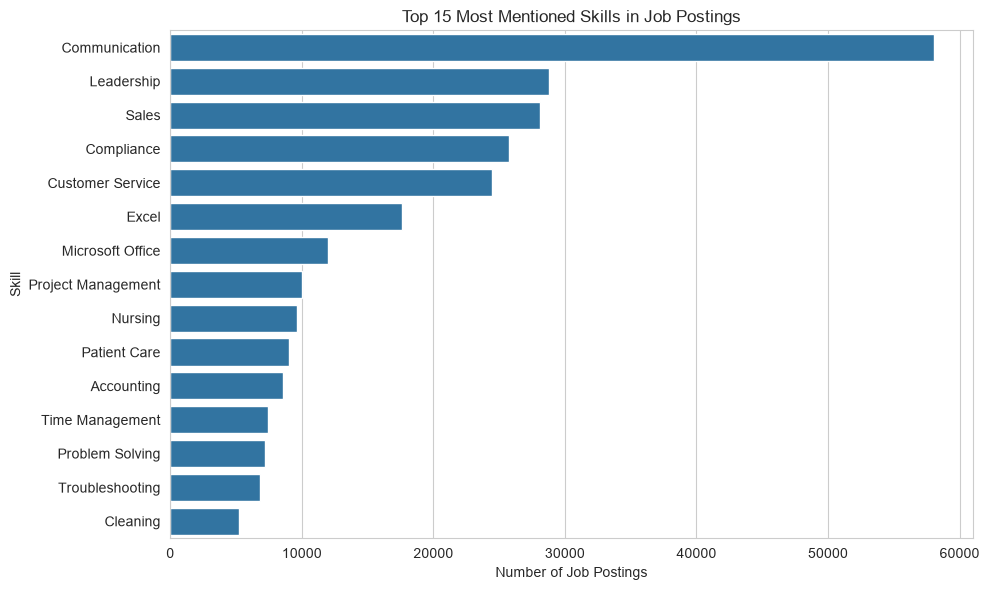

In [53]:
# Top 15 most mentioned skills
top_skills = (
    df_cleaned["extracted_skills"]
    .explode()
    .value_counts()
    .head(15)
)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_skills.values, y=top_skills.index)

plt.title("Top 15 Most Mentioned Skills in Job Postings")
plt.xlabel("Number of Job Postings")
plt.ylabel("Skill")
plt.tight_layout()
plt.show()

Communication is the most frequently mentioned skill, appearing in approximately 58,000 job postings, followed by Leadership and Sales. General workplace skills appear frequently across different roles in the dataset..

In [54]:
# Top 10 locations with reported USD salaries
top_salary_locations = (
    df_salary_analysis.loc[df_salary_analysis["location"] != "United States", "location"]
    .value_counts()
    .head(10)
)

# Median salary for each location
salary_by_location = (
    df_salary_analysis[df_salary_analysis["location"].isin(top_salary_locations.index)]
    .groupby("location")["normalized_salary"]
    .agg(["count", "median"])
    .sort_values("median", ascending=False)
)

salary_by_location

,count,median
location,,
"San Francisco, CA",394,130770.0
"Seattle, WA",422,125673.6
New York City Metropolitan Area,433,111562.5
"New York, NY",1487,110000.0
"Chicago, IL",449,100000.0
"Atlanta, GA",329,95000.0
"Los Angeles, CA",517,93600.0
"Houston, TX",338,85000.0
"San Diego, CA",379,84000.0


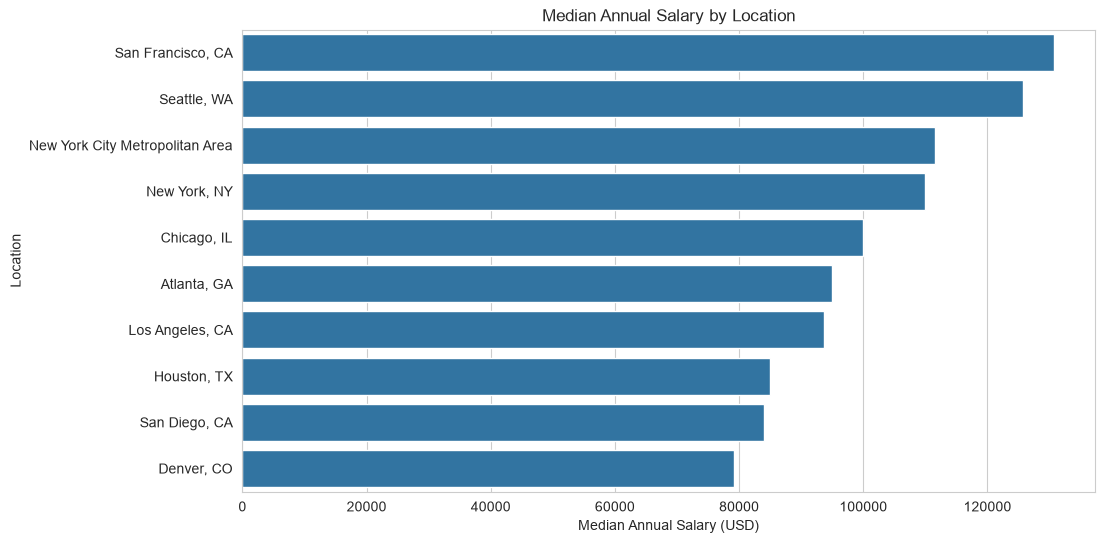

In [55]:
# Median Annual Salary by Location
plt.figure(figsize=(11, 6))

sns.barplot(
    data=salary_by_location.reset_index(),
    x="median",
    y="location"
)

plt.title("Median Annual Salary by Location")
plt.xlabel("Median Annual Salary (USD)")
plt.ylabel("Location")

plt.show()

San Francisco has the highest median annual salary among the selected locations ($130,770), followed by Seattle ($125,674). New York, NY has the most salary-reported job postings in this comparison, with 1,487 jobs.


In [56]:
# Align skills with the USD salary subset using original row indices
df_salary_analysis["extracted_skills"] = df_cleaned.loc[df_salary_analysis.index, "extracted_skills"]

salary_by_skill = (
    df_salary_analysis[["normalized_salary", "extracted_skills"]]
    .explode("extracted_skills")
    .dropna(subset=["extracted_skills"])
    .groupby("extracted_skills")["normalized_salary"]
    .agg(["count", "median"])
    .sort_values("median", ascending=False)
)
salary_by_skill.head(10)

,count,median
extracted_skills,,
Machine Learning,634,163105.0
Model Validation,17,162300.0
AWS,888,145000.0
Spark,242,143200.0
Java,685,141750.0
Circuit Design,33,140000.0
Python,1385,140000.0
Azure,776,137390.0
Cybersecurity,410,134750.0


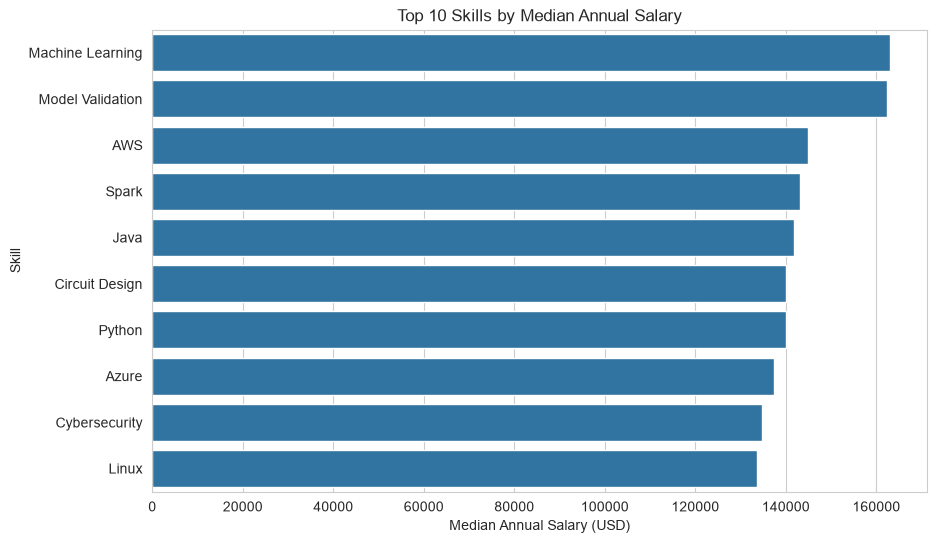

In [57]:
# Top 10 skills by median salary
top_salary_skills = salary_by_skill.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_salary_skills.reset_index(),
    x="median",
    y="extracted_skills"
)

plt.title("Top 10 Skills by Median Annual Salary")
plt.xlabel("Median Annual Salary (USD)")
plt.ylabel("Skill")

plt.show()

Machine Learning has the highest median annual salary ($163,105), followed by Model Validation ($162,300) and AWS ($145,000).

However, Model Validation appears in only 17 job postings, so we should be careful when comparing the results.

Jobs mentioning these skills tend to have higher salaries, but this does not mean the skills directly cause higher pay.


In [58]:
# Show numerical columns
df_cleaned.select_dtypes(include="number").columns

Index(['job_id', 'max_salary', 'views', 'med_salary', 'min_salary', 'applies',
       'remote_allowed', 'normalized_salary'],
      dtype='object')

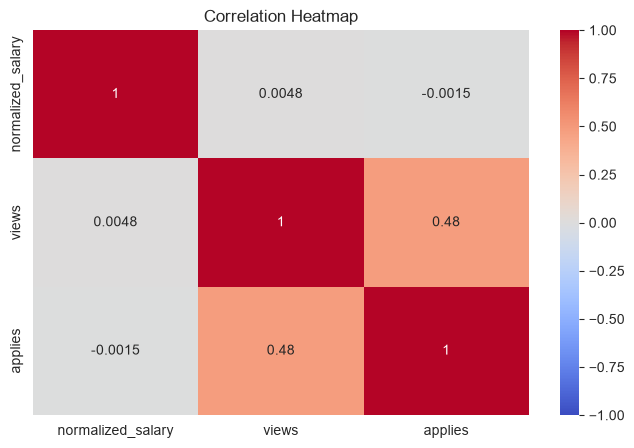

In [59]:
# Correlation between salary, views, and applications
correlation = df_salary_analysis[
    ["normalized_salary", "views", "applies"]
].corr()

plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap")
plt.show()

### Correlation Analysis

The heatmap shows Pearson correlations between reported annualized salaries, job views, and applications in the salary-analysis subset. Missing applications limit the sample and extreme values may affect the correlations. Correlation does not imply causation.


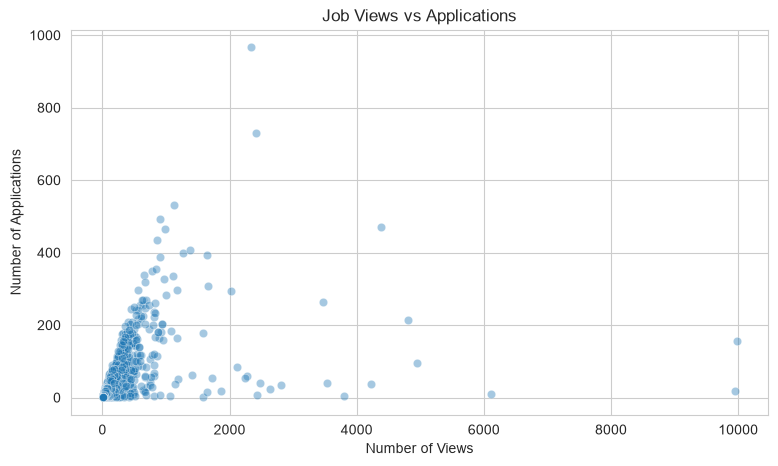

In [60]:
# Scatter plot: Job Views vs Applications
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df_salary_analysis,
    x="views",
    y="applies",
    alpha=0.4
)

plt.title("Job Views vs Applications")
plt.xlabel("Number of Views")
plt.ylabel("Number of Applications")

plt.show()

### Job Views vs Applications

The scatter plot shows the relationship between job views and applications within the analyzed salary subset. More views often accompany more applications, but outliers exist and the relationship does not establish causation.


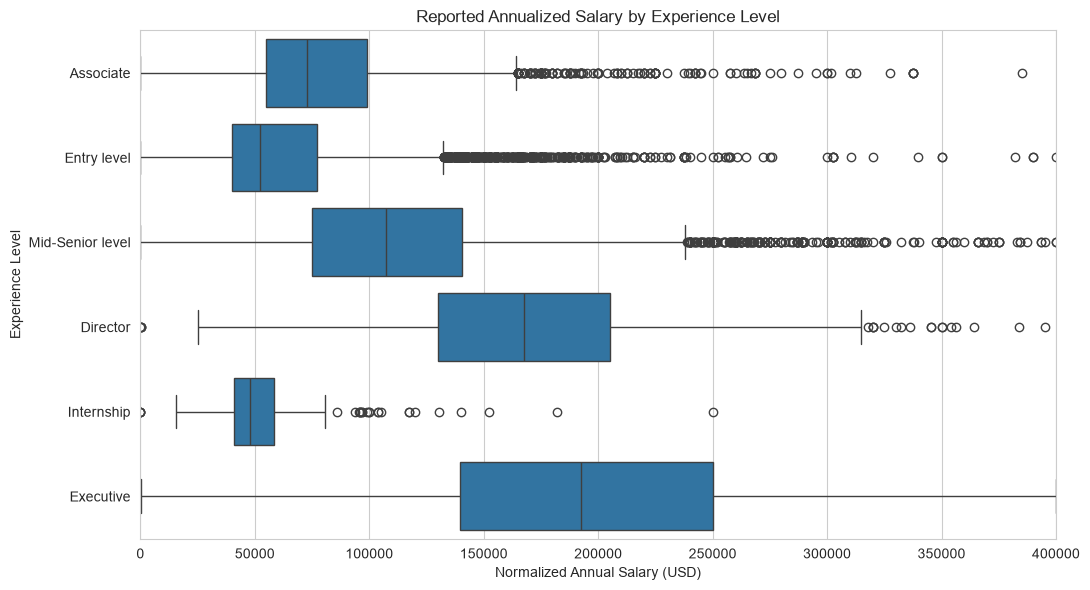

In [61]:
# Salary distributions across experience levels
# Suspicious pay-period records are excluded from this comparison; other outliers remain. The x-axis limit affects display only.
plt.figure(figsize=(11, 6))
sns.boxplot(
    data=df_salary_experience,
    x="normalized_salary",
    y="formatted_experience_level",
)
plt.xlim(0, 400000)
plt.title("Reported Annualized Salary by Experience Level")
plt.xlabel("Normalized Annual Salary (USD)")
plt.ylabel("Experience Level")
plt.tight_layout()
plt.show()

### Salary Distribution by Experience Level

Salaries generally increase with experience level. Executive and Director jobs have higher median salaries and a wider salary range than Entry-level and Internship jobs.

Some outliers are still present because not all high salaries are errors. We excluded only 35 potentially incorrect salary records from this analysis.

In [62]:
# Detect salary outliers using IQR
Q1 = df_salary["normalized_salary"].quantile(0.25)
Q3 = df_salary["normalized_salary"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Count outliers
outliers = df_salary[
    (df_salary["normalized_salary"] < lower_bound) |
    (df_salary["normalized_salary"] > upper_bound)
]

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Outliers:", len(outliers))
print("Outliers Percentage:", round(len(outliers) / len(df_salary) * 100, 2), "%")

Lower Bound: -57880.0
Upper Bound: 234728.0
Number of Outliers: 927
Outliers Percentage: 2.64 %


### Salary Outlier Analysis

Using the IQR method, I found 927 salary outliers (2.64%).

Not all outliers are errors, as some jobs may offer high salaries.

I excluded 35 potentially incorrect salary records from the main salary analysis and kept the remaining outliers.

In [63]:
# Sensitivity check ONLY; diagnostic on all USD salary records; does not remove IQR outliers
salary_without_outliers = df_salary.loc[
    df_salary["normalized_salary"].between(lower_bound, upper_bound)
]
print("Original mean:", df_salary["normalized_salary"].mean())
print("Mean excluding IQR flags (comparison only):", salary_without_outliers["normalized_salary"].mean())
print("Original median:", df_salary["normalized_salary"].median())
print("Median excluding IQR flags (comparison only):", salary_without_outliers["normalized_salary"].median())

Original mean: 208498.53794638274
Mean excluding IQR flags (comparison only): 89778.01215722442
Original median: 81740.1125
Median excluding IQR flags (comparison only): 80000.0


### Impact of Salary Outliers

The mean salary dropped from $208,499 to $89,778 when I excluded the IQR outliers for comparison.

However, the median changed only slightly, from $81,740 to $80,000.

This shows that the median is less affected by extreme salaries and is more useful for comparing salaries in this dataset.

### IQR Outlier Analysis

I used the IQR method and found 927 outliers (2.64%).

After checking the salaries, I found 35 records with possible errors in the pay periods, so I excluded them from the salary analysis only.

I kept the other outliers because high salaries are not always errors. I also used the median because it is less affected by extreme values.


## Final Insights

1. **Job Titles:** Sales Manager is the most common job title, with 632 postings.
2. **Locations:** New York has the highest number of job postings among the cities analyzed.
3. **Experience:** Most jobs with a known experience level are Mid-Senior or Entry-level.
4. **Salaries:** Jobs with higher experience levels generally offer higher salaries.
5. **Outliers:** I found 927 salary outliers and excluded 35 potentially incorrect records from salary comparisons.
6. **Skills:** Communication is the most mentioned skill, followed by Leadership and Sales.
7. **Applications:** Job views and applications have a moderate positive correlation (0.48), but salaries show almost no linear correlation with either.

These findings are based on this dataset and may not represent the entire job market.

## Limitations and Recommendations

### Limitations
- The dataset contains job postings from 2023–2024, so it may not reflect the current job market.
- Many job postings have missing salary and experience information.
- Some salaries may contain errors. I excluded 35 suspicious salary records from salary comparisons.
- Skills were extracted using keywords, so some skills may be missed or incorrectly matched.
- Some job titles have very few postings, which makes their results less reliable.

### Recommendations
- Improve the skills extraction to identify more skills accurately.
- Check suspicious salary records before using them.
- Show the number of job postings alongside percentages and salary comparisons.
- Use more recent data for future analysis.

## Export Cleaned Data for Streamlit

I saved the cleaned dataset as a CSV file to use in the Streamlit dashboard.

The file contains 120,497 job postings, including the extracted skills.

In [64]:
# Export the cleaned dataset without changing the in-memory list column
export_df = df_cleaned.copy()
export_df["extracted_skills"] = export_df["extracted_skills"].apply(
    lambda values: ";".join(values) if isinstance(values, list) else ""
)
export_file = "linkedin_job_postings_cleaned.csv"
export_df.to_csv(export_file, index=False)
print("Saved:", export_file)
print("Rows:", len(export_df), "Columns:", export_df.shape[1])

# Optional in Google Colab: uncomment to download the file to your computer
# from google.colab import files
# files.download(export_file)

Saved: linkedin_job_postings_cleaned.csv
Rows: 120497 Columns: 21
